# Binomial Option Tree Pricer Visualization

## Importing The Stuff
Start importing the appropriate stuff

In [39]:
from pathlib import Path
import sys

# Get the directory of the notebook, navigate up, and find 'src'
src_path = Path.cwd().parent / "src"

# Add to system path if it's not already there
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

# Import the other modules
import numpy as np 
import matplotlib.pyplot as plt
from scipy.special import binom

# The most important one
from binomial_option_pricer import binomial_option_pricer, call_payoff, put_payoff

## Inputting Parameters
Input your own parameters below:

- $S$: Spot price of stock
- $K$: Strike price of option
- $T$: Time span
- $N$: Number of time steps
- $\sigma$: Annualized Volatility of stock
- $r$: Continuous market risk-free rate
- call: True if this is a call option, False if put option
- european: True if this is a European-style option, False if American-style

In [40]:
S = 250
K = 250
T = 10

# Recommend to keep under 30 for legibility
N = 10

sigma = 0.1
r = 0.02
call = True
european = True

### Checking the No-Arbitrage Rule
Make sure to run the following code to see if your inputted parameters violate the No-Arbitrage rule. If all is good, then continue on. If not, then tweak your parameters.

Note that we are using the Cox-Ross-Rubinstein (CRR) parameterization for the up and down factors $u$ and $d$: $u = e^{\sigma \sqrt{dt}}, d=\frac{1}{u}=e^{-\sigma \sqrt{dt}}$ with $dt=T/N$.

In [41]:
R = np.exp(r*T/N)
u = np.exp(sigma*np.sqrt(T/N))
d = 1/u

if R <= d:
    raise ValueError("Arbitrage oppotunity (R <= d): Borrow money at the market risk-free rate and put it into the stock")
elif R >= u:
    raise ValueError("Arbitrage oppotunity (R >= u): Short-sell the stock and put that money in an investment returning the market risk-free rate")
else:
    print("No-Arbitrage Rule not violated!")


No-Arbitrage Rule not violated!


## Option Price Tree Visualization
The following block of code will plot the tree. For American-style options, nodes that are highlighted in red represents states where early exercising of the option is most optimal.

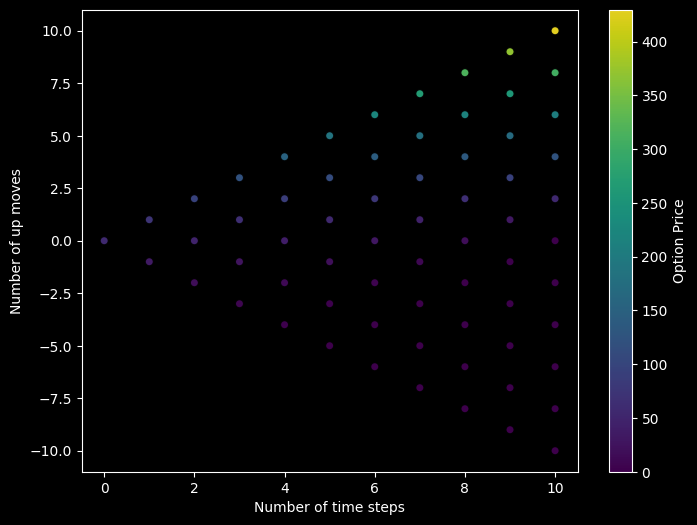

Starting price for option: 55.87992894866754


In [42]:
A = binomial_option_pricer(S=S, K=K, T=T, N=N, sigma=sigma, r=r, call=call, european=european)
tree = A.option_price_tree

option_price_tree_data = np.concatenate([tree[i,:i+1] for i in range(N+1)])
mark_nodes = np.concatenate([A.marked_nodes[i,:i+1] for i in range(N+1)])
Y_data = np.concatenate([[2*j-i for j in range(i+1)] for i in range(N+1)])
X_data = np.concatenate([np.full(i,i-1) for i in range(1,N+2)])

plt.style.use('dark_background')
plt.figure(figsize=(8, 6))

edgecolors = ["none" if mark_nodes[i] == 0 else "red" for i in range(((N+1)*(N+2))//2)]

scatter = plt.scatter(X_data,Y_data,c=option_price_tree_data, cmap='viridis',alpha=0.9,edgecolors=edgecolors)
colorbar = plt.colorbar(scatter)
colorbar.set_label("Option Price")
plt.xlabel("Number of time steps")
plt.ylabel("Number of up moves")
plt.grid(False)
plt.show()

print(f"Starting price for option: {A.V0}")

### Stock Price Tree Visualization
This is just for sake of extra comparison.

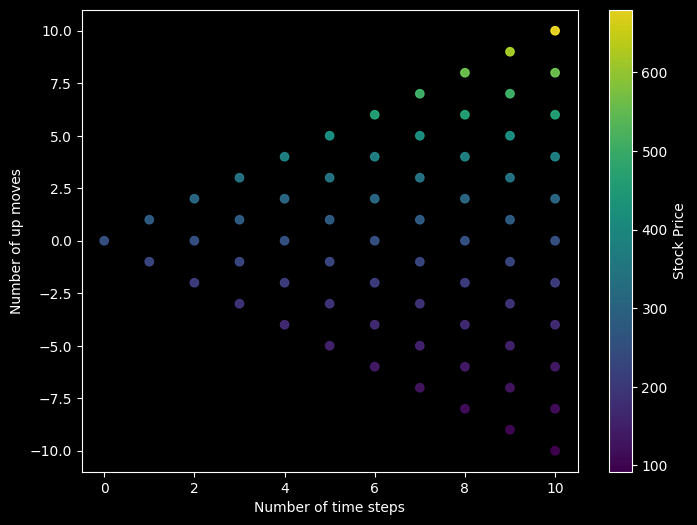

Starting price for stock: 250


In [43]:
tree = A.stock_price_tree

stock_price_tree_data = np.concatenate([tree[i,:i+1] for i in range(N+1)])
Y_data = np.concatenate([[2*j-i for j in range(i+1)] for i in range(N+1)])
X_data = np.concatenate([np.full(i,i-1) for i in range(1,N+2)])

plt.style.use('dark_background')
plt.figure(figsize=(8, 6))


scatter = plt.scatter(X_data,Y_data,c=stock_price_tree_data, cmap='viridis',alpha=0.9)
colorbar = plt.colorbar(scatter)
colorbar.set_label("Stock Price")
plt.xlabel("Number of time steps")
plt.ylabel("Number of up moves")
plt.grid(False)
plt.show()

print(f"Starting price for stock: {A.S}")

## Numerical Comparison with Continuous Black-Scholes Model
Now that we have our discrete time model, we will compare it with the continuous time model with Black-Scholes.

The formula using Black-Scholes for a European Call option is:

$$C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2)$$

where $d_1=\frac{\ln(S/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2=d_1-\sigma\sqrt{T}$. Note that $\Phi$ denotes the standard normal cumulative distribution function accessible using `scipy.stats.norm.cdf`.

In [44]:
# Import the Black-Scholes Model
from black_scholes_pricer import black_scholes_european_price

Text(0, 0.5, 'Absolste Error')

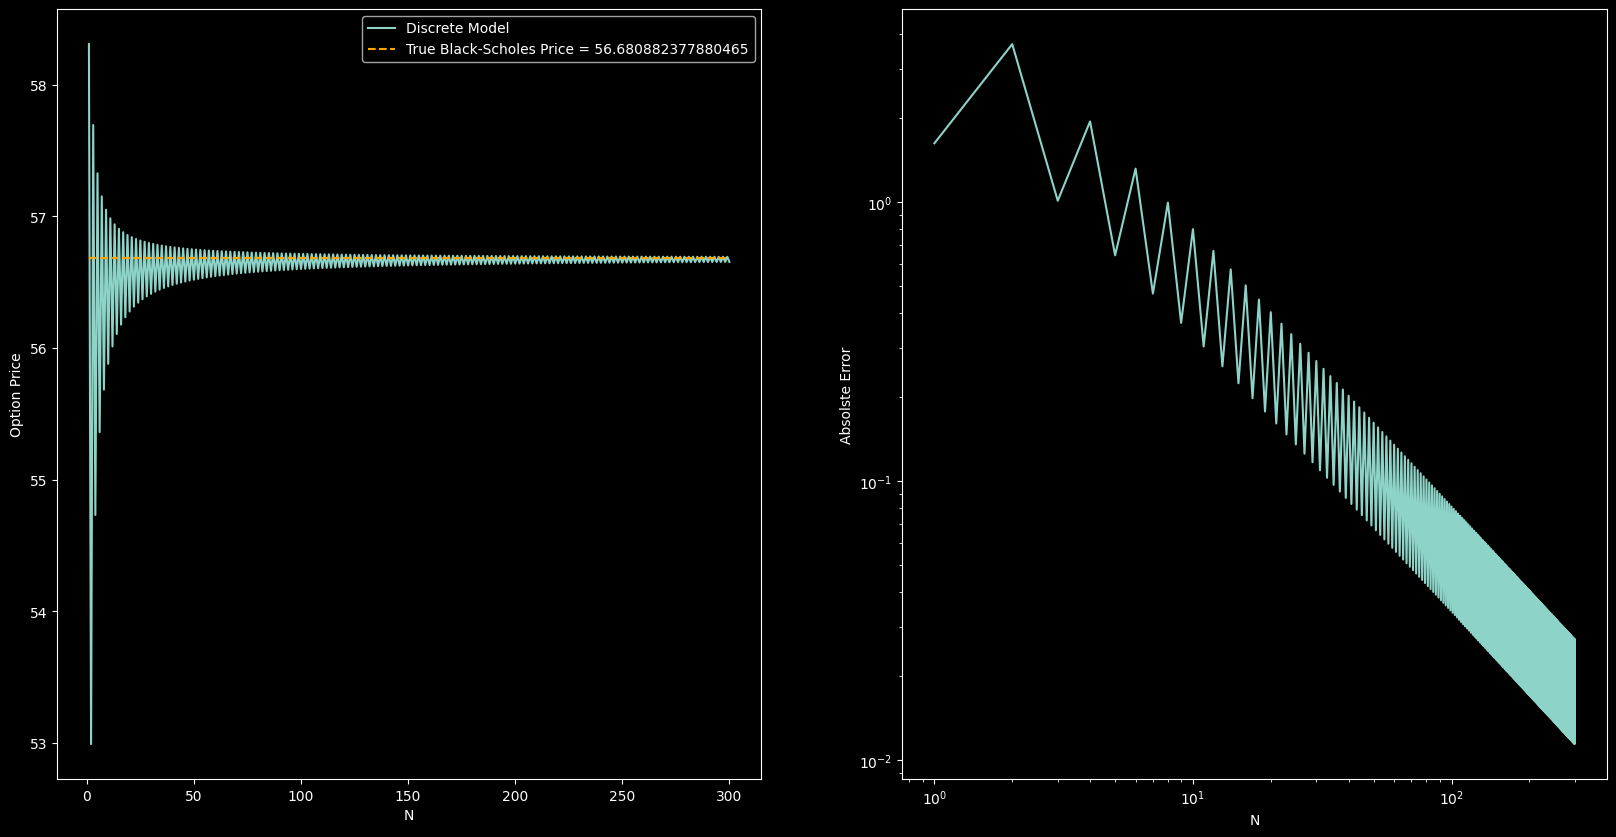

In [ ]:
# Our baseline Black-Scholes price that are discrete model should converge to as N increases
true_V = black_scholes_european_price(S=S,K=K,r=r,T=T,sigma=sigma,call=call)

# Maximum value of N
maxN = 300

# Setup plotting
fig,ax = plt.subplots(1,2,figsize=(20,10))

# Generate our X_data which is N-values, and Y_data containing our option prices
X_data = np.array(range(1,maxN+1))
Y_data = np.zeros(maxN)

for i in range(1,maxN+1):
    discrete_model = binomial_option_pricer(T=T,K=K,N=i,S=S,sigma=sigma,r=r,call=call,european=True)
    Y_data[i-1] = discrete_model.V0

# Show convergence of discrete model to continuous model
ax[0].plot(X_data,Y_data,label="Discrete Model")
ax[0].plot(X_data,maxN*[true_V],color="orange",linestyle="--",label=f"True Black-Scholes Price = {true_V}")
ax[0].set_xlabel("N")
ax[0].set_ylabel("Option Price")
ax[0].legend()

# Show how the absolte error changes vs N
Y_data = np.abs(Y_data - true_V)
ax[1].plot(X_data,Y_data)
ax[1].set_yscale("log")
ax[1].set_xscale("log")
ax[1].set_xlabel("N")
ax[1].set_ylabel("Absolste Error")

